# Loan Default and Risk Category Classification
### Bank Loan Applications (2022–2024)


## 1. Import libraries

In [33]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Loan_Data sheet

In [3]:
# Keep blank strings visible initially so that text 'N/A' and blanks can be handled deliberately.
FILE_PATH = "Classification_practice data.xlsx"  # Change this path if your Excel file is elsewhere
raw = pd.read_excel(FILE_PATH, sheet_name="Loan_Data", keep_default_na=False)

print("Original shape:", raw.shape)
display(raw.head())

Original shape: (10100, 41)


,Applicant_ID,Application_Date,Branch_Code,Application_Channel,Age,Gender,Marital_Status,Education_Level,Dependents,Region,Residence_Years,Home_Ownership,Employment_Type,Employer_Sector,Years_Employed,Annual_Income,Salary_Account_With_Bank,Vehicle_Owned,Loan_Purpose,Loan_Amount,Loan_Term_Months,Interest_Rate_Pct,Property_Value,Has_Co_Applicant,Credit_Score,Credit_History_Years,Existing_Loans,Total_Credit_Limit,Credit_Utilization_Pct,Credit_Inquiries_6M,Late_Payments_2Y,Months_Since_Last_Delinquency,Previous_Default,Monthly_Debt_Payment,Savings_Balance,Checking_Balance,Overdrafts_12M,Bank_Relationship_Years,Mobile_Banking_User,Loan_Default,Risk_Category
0,LN-114369,2023-12-18,BR-01,Branch,57,Female,,Master,2,Rural,13.4,Own,Retired,Not applicable,32.8,51800,No,No,Personal,11500,12,10.29,,No,627,4.3,1,18500,47.3,0,0,,No,320,24390,6890,0,2.6,Yes,No,Low
1,LN-136223,2022-11-12,BR-20,Online,45,Male,Married,Diploma,2,Rural,9.3,Mortgage,Self-Employed,Services,16.6,,No,No,Personal,11500,12,6.89,,No,728,9.8,1,26500,29.3,0,0,,No,190,10120,560,0,2.4,No,No,Low
2,LN-103022,2022-11-01,BR-01,Online,63,Female,Married,Bachelor,1,Rural,12.4,Own,Salaried,Services,6.4,18400,No,No,Auto,10000,36,6.52,,No,758,4.2,2,5000,27.5,1,0,,No,215,13440,690,0,0.8,Yes,No,Low
3,LN-107320,2022-11-22,BR-05,Online,51,Female,Married,High School,0,Urban,8.5,Own,Self employed,Services,6,20400,No,Yes,Auto,12000,36,9.96,,No,575,4.9,0,5000,59.7,1,1,1,No,35,2000,400,0,1.9,No,No,High
4,LN-129811,2023-06-30,BR-03,Branch,34,Male,Married,Diploma,1,Suburban,8.1,Mortgage,Contract,Services,14,45300,No,Yes,Education,22000,60,4.05,,No,816,8.9,1,25000,8.5,0,0,,No,460,85150,1180,0,5.6,No,No,Low


## 3. Inspect the dataset

In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10100 entries, 0 to 10099
Data columns (total 41 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Applicant_ID                   10100 non-null  object        
 1   Application_Date               10100 non-null  datetime64[ns]
 2   Branch_Code                    10100 non-null  object        
 3   Application_Channel            10100 non-null  object        
 4   Age                            10100 non-null  int64         
 5   Gender                         10100 non-null  object        
 6   Marital_Status                 10100 non-null  object        
 7   Education_Level                10100 non-null  object        
 8   Dependents                     10100 non-null  int64         
 9   Region                         10100 non-null  object        
 10  Residence_Years                10100 non-null  object        
 11  Home_Ownership 

In [5]:
display(raw.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Applicant_ID,10100,10000,LN-109191,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Application_Date,10100,NaN,NaN,NaN,2023-06-24 15:02:55.366336768,2022-01-03 00:00:00,2022-09-26 18:00:00,2023-06-21 00:00:00,2024-03-21 00:00:00,2024-12-27 00:00:00,NaN
Branch_Code,10100,40,BR-01,1668,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Application_Channel,10100,3,Branch,4548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10100.0,NaN,NaN,NaN,43.44495,3.0,35.0,42.0,50.0,212.0,10.767803
Gender,10100,8,Male,5199,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,10100,5,Married,5886,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,10100,6,Bachelor,3140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,10100.0,NaN,NaN,NaN,1.152772,0.0,0.0,1.0,2.0,5.0,1.042197
Region,10100,3,Urban,5036,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Repeated Applicant_ID values:", raw["Applicant_ID"].duplicated().sum())
print("\nMissing/blank-like values by column:")
blank_counts = raw.astype(str).apply(lambda col: col.str.strip().isin(["", "N/A", "n/a", "NA", "na"]).sum())
display(blank_counts[blank_counts > 0].sort_values(ascending=False))

Exact duplicate rows: 100
Repeated Applicant_ID values: 100

Missing/blank-like values by column:


Property_Value                   8308
Months_Since_Last_Delinquency    7247
Savings_Balance                   614
Years_Employed                    530
Annual_Income                     466
Education_Level                   385
Residence_Years                   384
Credit_History_Years              315
Total_Credit_Limit                312
Credit_Score                      285
Checking_Balance                  273
Credit_Inquiries_6M               201
Marital_Status                    104
dtype: int64

,Missing_Count,Missing_Percent
Property_Value,8308,82.26
Months_Since_Last_Delinquency,7247,71.75
Savings_Balance,614,6.08
Years_Employed,530,5.25
Annual_Income,466,4.61
Education_Level,385,3.81
Residence_Years,384,3.80
Credit_History_Years,315,3.12
Total_Credit_Limit,312,3.09
Credit_Score,285,2.82


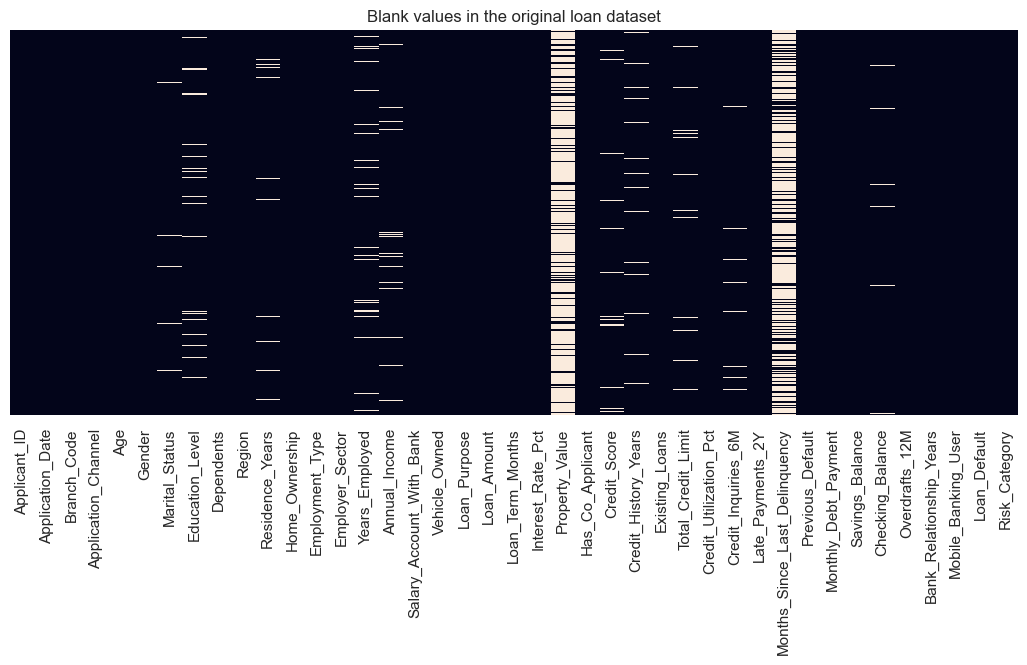

In [7]:
missing_summary = pd.DataFrame({
    "Missing_Count": blank_counts,
    "Missing_Percent": (blank_counts / len(raw) * 100).round(2)
}).sort_values("Missing_Count", ascending=False)
display(missing_summary[missing_summary["Missing_Count"] > 0])

plt.figure(figsize=(13, 5))
sns.heatmap(raw.replace(r"^\s*$", np.nan, regex=True).isna(), cbar=False, yticklabels=False)
plt.title("Blank values in the original loan dataset")
plt.show()

**Interpretation:** The workbook contains about 10,100 applications and 41 columns. The supplied data-problem catalogue identifies 100 duplicate rows, missing values, inconsistent category labels, invalid numeric values, structural blanks and class imbalance. We will address these explicitly rather than deleting large numbers of applicants.

## 4. Clean the data

In [8]:
# Work on a copy; never overwrite the original Excel file.
df = raw.copy()

# Standardise blank and text-coded missing values.
df = df.replace(r"^\s*$", np.nan, regex=True)
df = df.replace({"N/A": np.nan, "n/a": np.nan, "NA": np.nan, "na": np.nan})

# Remove exact duplicate rows before splitting to avoid the same record appearing in train and test.
df = df.drop_duplicates().copy()
print("Shape after removing exact duplicates:", df.shape)

# Standardise text fields: trim leading/trailing spaces.
text_cols = df.select_dtypes(include=["object"]).columns
for col in text_cols:
    df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

# Standardise Gender variants.
gender_map = {
    "m": "Male", "male": "Male",
    "f": "Female", "female": "Female"
}
df["Gender"] = df["Gender"].astype("string").str.lower().map(gender_map)

# Standardise known spelling/case variants in categorical fields.
df["Employment_Type"] = df["Employment_Type"].replace({
    "Self employed": "Self-Employed", "self-employed": "Self-Employed",
    "salaried": "Salaried"
})
df["Employer_Sector"] = df["Employer_Sector"].replace({
    "IT / Finance": "IT/Finance", "public sector": "Public Sector"
})

# Convert expected numeric columns safely. Invalid strings become missing.
numeric_cols_expected = [
    "Age", "Dependents", "Residence_Years", "Years_Employed", "Annual_Income",
    "Loan_Amount", "Loan_Term_Months", "Interest_Rate_Pct", "Property_Value",
    "Credit_Score", "Credit_History_Years", "Existing_Loans", "Total_Credit_Limit",
    "Credit_Utilization_Pct", "Credit_Inquiries_6M", "Late_Payments_2Y",
    "Months_Since_Last_Delinquency", "Monthly_Debt_Payment", "Savings_Balance",
    "Checking_Balance", "Overdrafts_12M", "Bank_Relationship_Years"
]
for col in numeric_cols_expected:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Correct impossible/sentinel values.
df.loc[~df["Age"].between(18, 90), "Age"] = np.nan
df.loc[df["Credit_Score"] == 9999, "Credit_Score"] = np.nan
df.loc[df["Years_Employed"] < 0, "Years_Employed"] = np.nan

# Interest rate mixes fractions (e.g. 0.07) and percentages (7.0).
df.loc[df["Interest_Rate_Pct"] < 1, "Interest_Rate_Pct"] *= 100

# Structural missingness: no delinquency recorded means no previous delinquency.
df["Ever_Delinquent"] = df["Months_Since_Last_Delinquency"].notna().astype(int)
df["Months_Since_Last_Delinquency"] = df["Months_Since_Last_Delinquency"].fillna(0)

# Structural missingness: property value applies to home loans.
df["Is_Home_Loan"] = (df["Loan_Purpose"].astype("string").str.lower() == "home").astype(int)
df["Property_Value"] = df["Property_Value"].fillna(0)
df["Loan_to_Value"] = np.where(
    (df["Is_Home_Loan"] == 1) & (df["Property_Value"] > 0),
    df["Loan_Amount"] / df["Property_Value"],
    0
)

# Derive date features, then remove the raw date.
df["Application_Date"] = pd.to_datetime(df["Application_Date"], errors="coerce")
df["Application_Year"] = df["Application_Date"].dt.year
df["Application_Month"] = df["Application_Date"].dt.month
df = df.drop(columns=["Application_Date"])

# Target labels should be clean and consistently capitalised.
for target_col in ["Loan_Default", "Risk_Category"]:
    df[target_col] = df[target_col].astype("string").str.strip()

print("Cleaned shape:", df.shape)
display(df.head())

Shape after removing exact duplicates: (10000, 41)
Cleaned shape: (10000, 45)


,Applicant_ID,Branch_Code,Application_Channel,Age,Gender,Marital_Status,Education_Level,Dependents,Region,Residence_Years,Home_Ownership,Employment_Type,Employer_Sector,Years_Employed,Annual_Income,Salary_Account_With_Bank,Vehicle_Owned,Loan_Purpose,Loan_Amount,Loan_Term_Months,Interest_Rate_Pct,Property_Value,Has_Co_Applicant,Credit_Score,Credit_History_Years,Existing_Loans,Total_Credit_Limit,Credit_Utilization_Pct,Credit_Inquiries_6M,Late_Payments_2Y,Months_Since_Last_Delinquency,Previous_Default,Monthly_Debt_Payment,Savings_Balance,Checking_Balance,Overdrafts_12M,Bank_Relationship_Years,Mobile_Banking_User,Loan_Default,Risk_Category,Ever_Delinquent,Is_Home_Loan,Loan_to_Value,Application_Year,Application_Month
0,LN-114369,BR-01,Branch,57.0,Female,NaN,Master,2,Rural,13.4,Own,Retired,Not applicable,32.8,51800.0,No,No,Personal,11500,12,10.29,0.0,No,627.0,4.3,1,18500.0,47.3,0.0,0,0.0,No,320,24390.0,6890.0,0,2.6,Yes,No,Low,0,0,0.0,2023,12
1,LN-136223,BR-20,Online,45.0,Male,Married,Diploma,2,Rural,9.3,Mortgage,Self-Employed,Services,16.6,NaN,No,No,Personal,11500,12,6.89,0.0,No,728.0,9.8,1,26500.0,29.3,0.0,0,0.0,No,190,10120.0,560.0,0,2.4,No,No,Low,0,0,0.0,2022,11
2,LN-103022,BR-01,Online,63.0,Female,Married,Bachelor,1,Rural,12.4,Own,Salaried,Services,6.4,18400.0,No,No,Auto,10000,36,6.52,0.0,No,758.0,4.2,2,5000.0,27.5,1.0,0,0.0,No,215,13440.0,690.0,0,0.8,Yes,No,Low,0,0,0.0,2022,11
3,LN-107320,BR-05,Online,51.0,Female,Married,High School,0,Urban,8.5,Own,Self-Employed,Services,6.0,20400.0,No,Yes,Auto,12000,36,9.96,0.0,No,575.0,4.9,0,5000.0,59.7,1.0,1,1.0,No,35,2000.0,400.0,0,1.9,No,No,High,1,0,0.0,2022,11
4,LN-129811,BR-03,Branch,34.0,Male,Married,Diploma,1,Suburban,8.1,Mortgage,Contract,Services,14.0,45300.0,No,Yes,Education,22000,60,4.05,0.0,No,816.0,8.9,1,25000.0,8.5,0.0,0,0.0,No,460,85150.0,1180.0,0,5.6,No,No,Low,0,0,0.0,2023,6


**Cleaning decisions from the data-problem catalogue**
- Keep negative `Checking_Balance`: it can represent an overdrawn account.
- Do not median-impute `Months_Since_Last_Delinquency` or `Property_Value` before creating their structural indicators.
- Treat age outside 18–90, `Credit_Score=9999`, and negative `Years_Employed` as invalid/missing.
- Keep genuine high incomes; use robust imputation and scaling rather than deleting applicants.
- Missing-value imputation and scaling are fitted later on training data only.

## 5. Check the cleaned data

In [9]:
print("Duplicate rows remaining:", df.duplicated().sum())
print("\nMissing values after cleaning (before model imputation):")
display(df.isna().sum()[df.isna().sum() > 0].sort_values(ascending=False))
print("\nTarget counts:")
display(df["Loan_Default"].value_counts(dropna=False))
display(df["Risk_Category"].value_counts(dropna=False))

Duplicate rows remaining: 0

Missing values after cleaning (before model imputation):


Savings_Balance         605
Years_Employed          529
Annual_Income           463
Education_Level         381
Residence_Years         378
Credit_History_Years    312
Total_Credit_Limit      307
Credit_Score            289
Checking_Balance        272
Credit_Inquiries_6M     199
Marital_Status          103
Age                       3
dtype: int64


Target counts:


Loan_Default
No     8022
Yes    1978
Name: count, dtype: Int64

Risk_Category
Low       5013
Medium    2987
High      2000
Name: count, dtype: Int64

## 6. Exploratory Data Analysis (EDA)

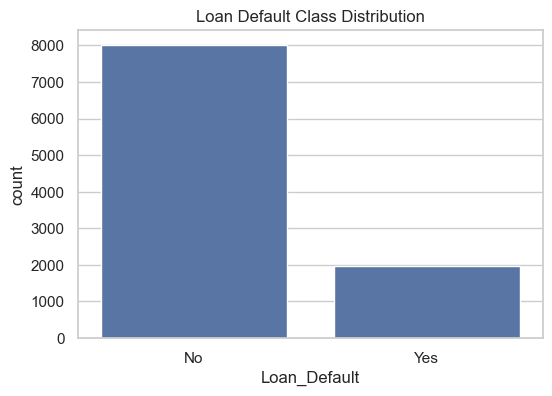

Loan_Default proportions:


Loan_Default
No     80.22
Yes    19.78
Name: proportion, dtype: Float64

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Default")
plt.title("Loan Default Class Distribution")
plt.show()

print("Loan_Default proportions:")
display(df["Loan_Default"].value_counts(normalize=True).mul(100).round(2))

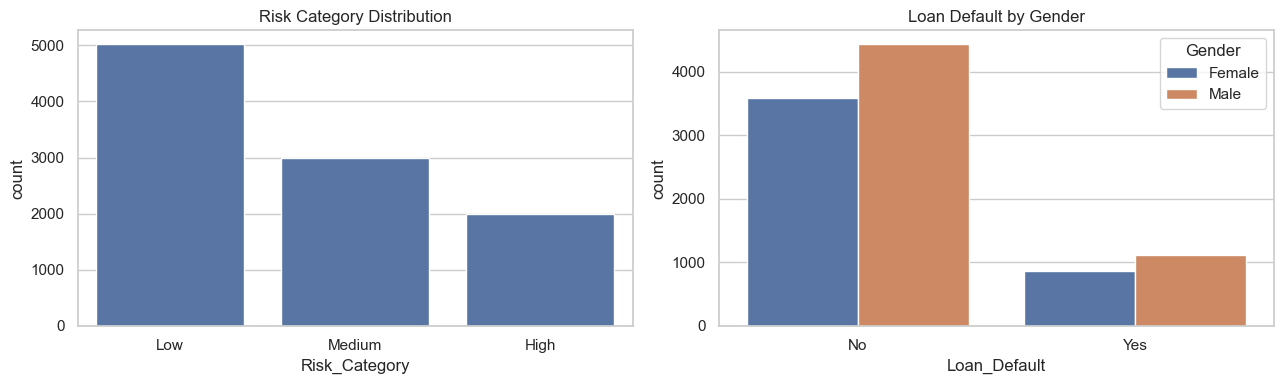

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Risk_Category", order=["Low", "Medium", "High"], ax=axes[0])
axes[0].set_title("Risk Category Distribution")
sns.countplot(data=df, x="Loan_Default", hue="Gender", ax=axes[1])
axes[1].set_title("Loan Default by Gender")
plt.tight_layout()
plt.show()

In [12]:
# Default rate by selected categorical variables.
for col in ["Loan_Purpose", "Employment_Type", "Region", "Home_Ownership", "Application_Channel"]:
    rate = df.groupby(col, dropna=False)["Loan_Default"].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
    display((rate * 100).round(2).rename("Default_Rate_Percent").to_frame())

,Default_Rate_Percent
Loan_Purpose,
Business,29.23
Home,24.53
Auto,17.68
Education,17.61
Medical,16.18
Personal,15.19


,Default_Rate_Percent
Employment_Type,
Unemployed,47.61
Contract,23.03
Self-Employed,21.45
Salaried,15.76
Retired,10.41


,Default_Rate_Percent
Region,
Suburban,20.50
Urban,19.89
Rural,18.42


,Default_Rate_Percent
Home_Ownership,
Mortgage,21.04
Rent,19.11
Own,18.99


,Default_Rate_Percent
Application_Channel,
Online,20.07
Branch,19.69
Agent,19.36


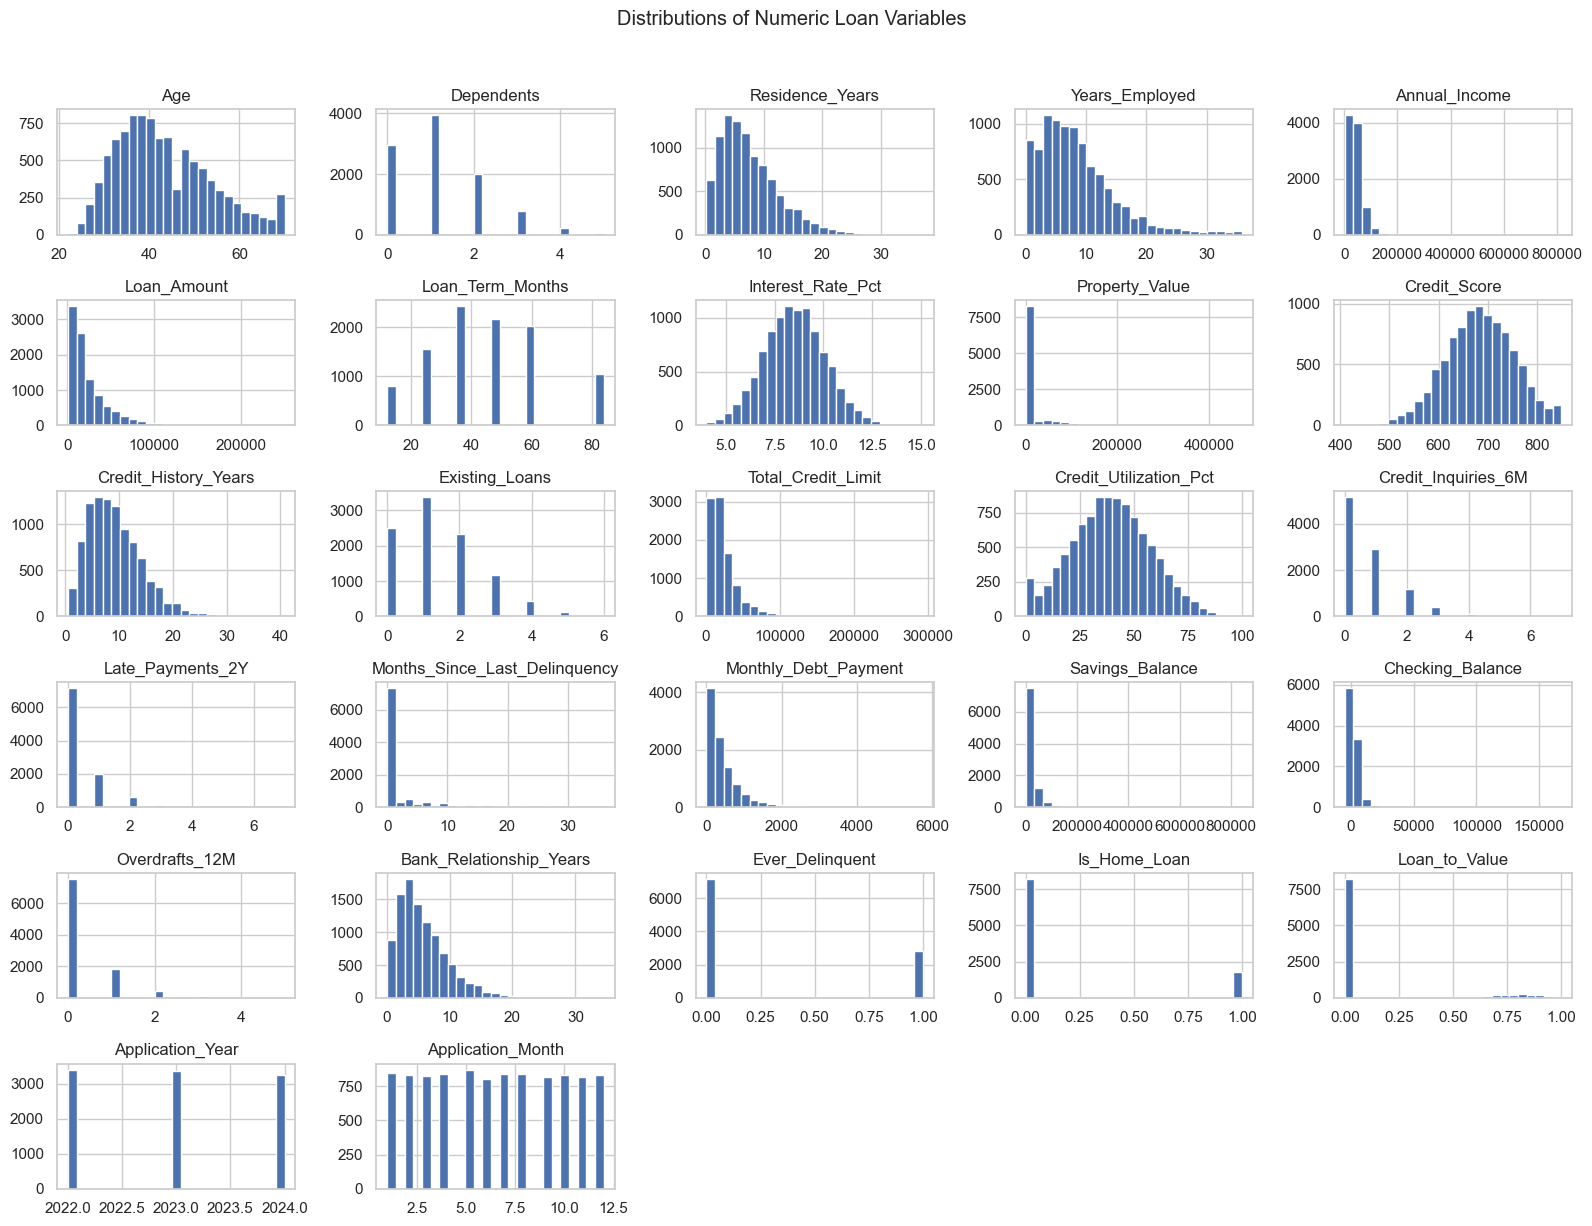

In [13]:
numeric_eda = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_eda].hist(figsize=(16, 12), bins=25)
plt.suptitle("Distributions of Numeric Loan Variables", y=1.02)
plt.tight_layout()
plt.show()

## 7. Skewness and outlier inspection

,Skewness
Checking_Balance,10.886137
Savings_Balance,6.567277
Annual_Income,4.589207
Total_Credit_Limit,2.850348
Monthly_Debt_Payment,2.621113
Loan_Amount,2.591248


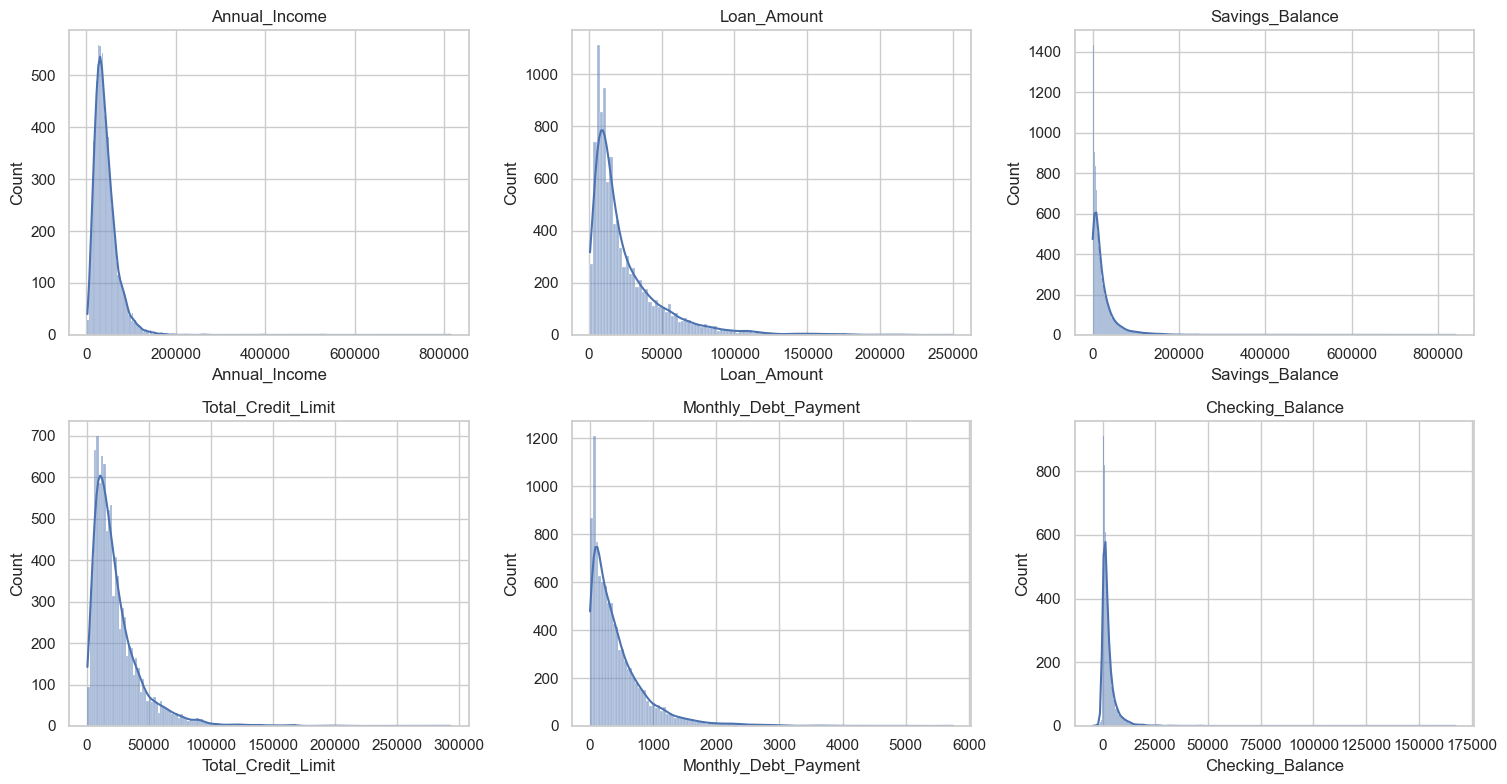

In [14]:
money_cols = ["Annual_Income", "Loan_Amount", "Savings_Balance", "Total_Credit_Limit",
              "Monthly_Debt_Payment", "Checking_Balance"]
skew_table = df[money_cols].skew(numeric_only=True).sort_values(ascending=False).to_frame("Skewness")
display(skew_table)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(money_cols, axes.ravel()):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

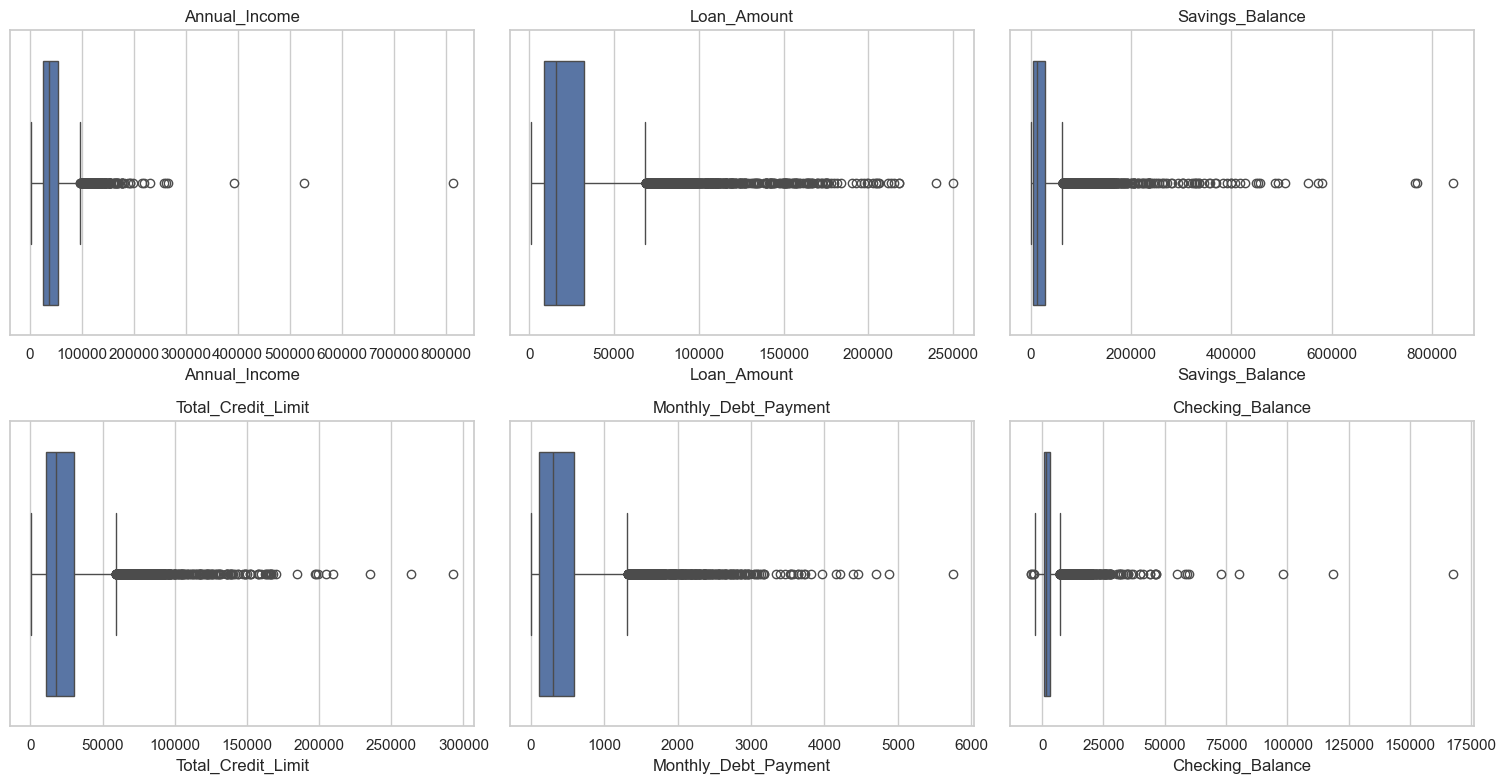

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, ax in zip(money_cols, axes.ravel()):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Interpretation:** Skewed money variables and extreme but genuine incomes can affect distance-based and linear models. We retain observations, use median imputation and standardisation inside the training pipeline, and compare models empirically. Negative checking balances are retained because they may indicate overdraft behaviour.

## 8. Feature engineering

In [16]:
# Lending-related ratios/flags already created during cleaning:
engineered_cols = ["Ever_Delinquent", "Is_Home_Loan", "Loan_to_Value",
                   "Application_Year", "Application_Month"]
print("Engineered features:", engineered_cols)
display(df[engineered_cols].head())

Engineered features: ['Ever_Delinquent', 'Is_Home_Loan', 'Loan_to_Value', 'Application_Year', 'Application_Month']


,Ever_Delinquent,Is_Home_Loan,Loan_to_Value,Application_Year,Application_Month
0,0,0,0.0,2023,12
1,0,0,0.0,2022,11
2,0,0,0.0,2022,11
3,1,0,0.0,2022,11
4,0,0,0.0,2023,6


The features add lending meaning:
- `Ever_Delinquent`: whether a delinquency record exists.
- `Is_Home_Loan`: identifies applications where property collateral is relevant.
- `Loan_to_Value`: requested loan divided by property value for home loans; zero otherwise.
- `Application_Year` and `Application_Month`: capture application timing without using the raw date.

## 9. Correlation and multicollinearity check

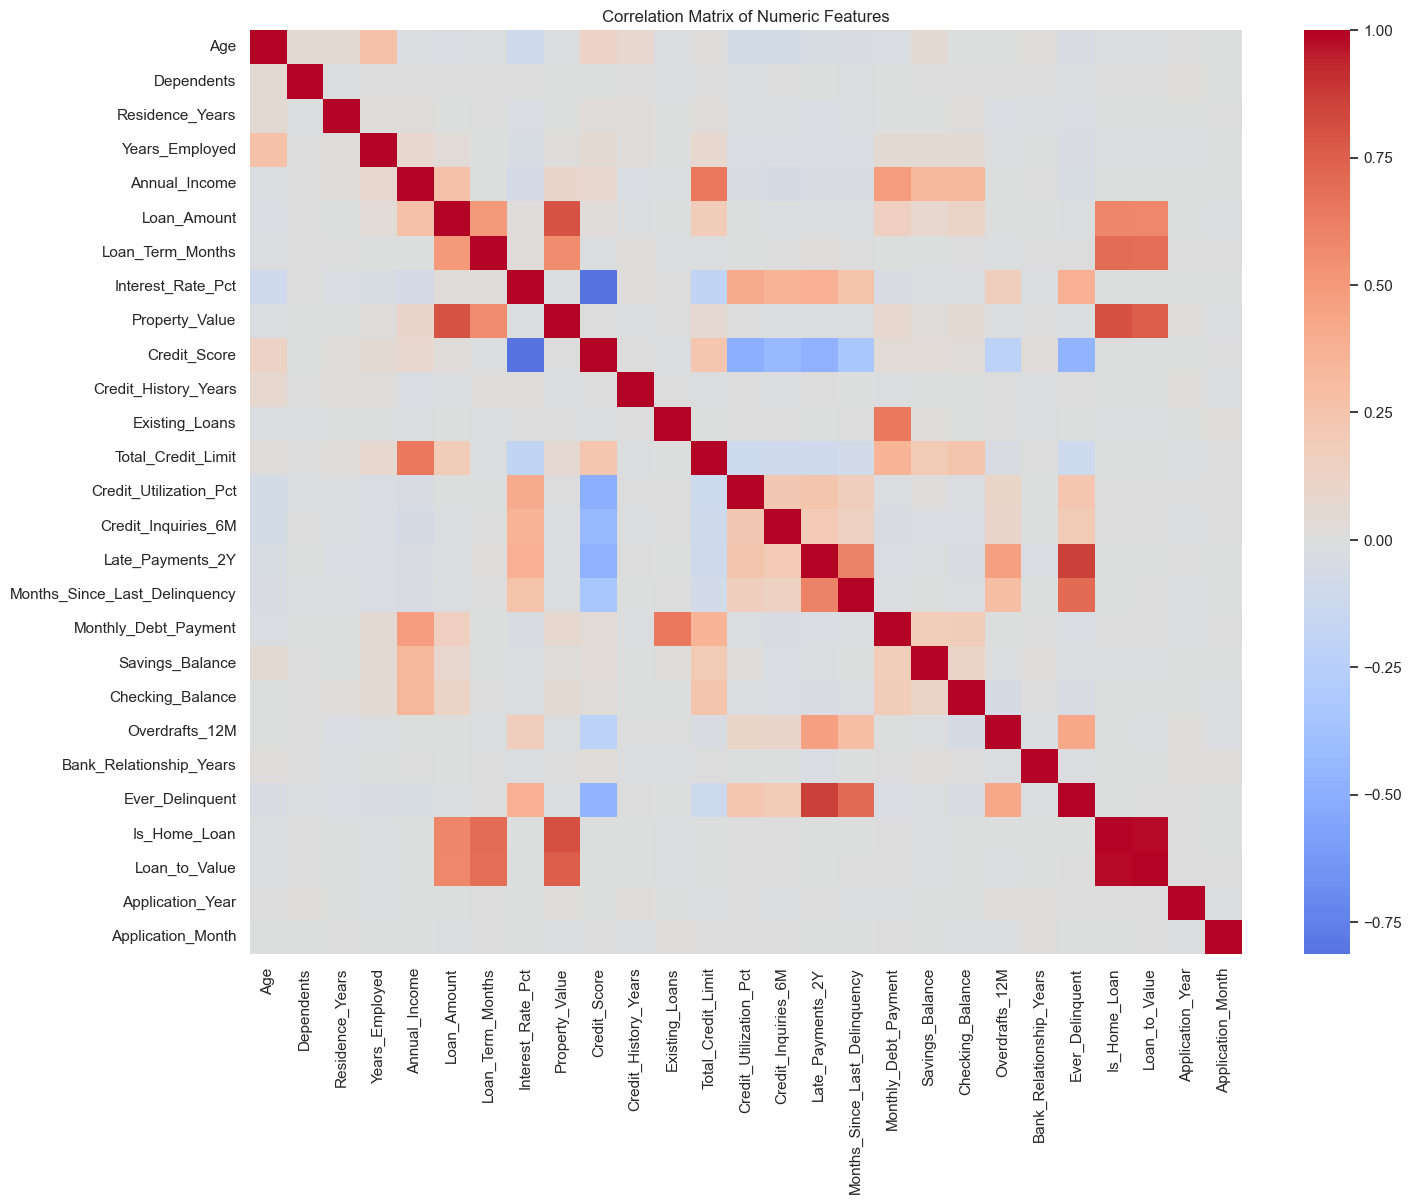

In [17]:
# Numeric correlation matrix; target labels and identifiers are not included.
corr_cols = [c for c in df.select_dtypes(include=np.number).columns if c != "Applicant_ID"]
corr = df[corr_cols].corr()
plt.figure(figsize=(16, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Matrix of Numeric Features")
plt.show()

In [18]:
# Show highly correlated numeric pairs for review.
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = (
    upper.stack().reset_index()
    .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2", 0: "Correlation"})
)
display(high_corr_pairs[high_corr_pairs["Correlation"].abs() >= 0.80]
        .sort_values("Correlation", key=lambda s: s.abs(), ascending=False))

,Feature_1,Feature_2,Correlation
345,Is_Home_Loan,Loan_to_Value,0.984671
291,Late_Payments_2Y,Ever_Delinquent,0.859690
162,Interest_Rate_Pct,Credit_Score,-0.812840
194,Property_Value,Is_Home_Loan,0.805855


**Interpretation:** Correlation is a diagnostic, not an automatic instruction to delete variables. In particular, `Loan_Amount` and `Property_Value`, and `Late_Payments_2Y` and `Ever_Delinquent`, may carry overlapping information. We retain them for the initial predictive comparison and use regularisation/tree models; any removal should be justified by the correlation results and domain meaning.

## 10. Prepare features and target for Loan_Default

In [19]:
# Exclude both outcomes and the applicant identifier. Risk_Category is target leakage for default prediction.
drop_for_default = ["Loan_Default", "Risk_Category", "Applicant_ID"]
X = df.drop(columns=drop_for_default, errors="ignore").copy()
y = df["Loan_Default"].map({"No": 0, "Yes": 1})

# Remove rows with an unavailable target only; do not use target columns as predictors.
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("X train:", X_train.shape, "X test:", X_test.shape)
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))

X train: (8000, 42) X test: (2000, 42)

Training target proportions:


Loan_Default
0    0.80225
1    0.19775
Name: Proportion, dtype: float64

## 11. Preprocessing pipeline

In [20]:
# Identify column types from the training data only.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_preprocessor = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

categorical_preprocessor = SkPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    
    ("num", numeric_preprocessor, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
], sparse_threshold=0.0)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 27
Categorical features: 15


Imputation, one-hot encoding and scaling are fitted only on training folds by the pipeline. This prevents information from the test set leaking into model training. `Branch_Code` is one-hot encoded here; it has 40 categories, which is manageable for this dataset and avoids target encoding outside cross-validation.

## 12. Class imbalance and SMOTE

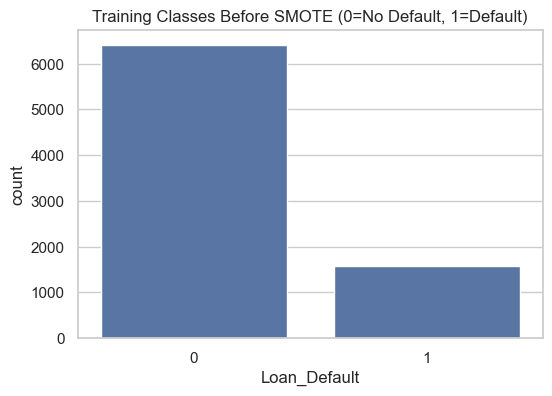

Before SMOTE:


Loan_Default
0    6418
1    1582
Name: count, dtype: int64

In [46]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Training Classes Before SMOTE (0=No Default, 1=Default)")
plt.show()
print("Before SMOTE:")
display(y_train.value_counts())

The default class is the minority class (about 19.8%). Accuracy alone is misleading because a model that predicts every applicant as non-default would achieve roughly 80% accuracy but detect no defaulters. SMOTE is applied **inside the training pipeline only**; the test set keeps the original class distribution.

## 13. Train at least four classification algorithms

In [49]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight=None, random_state=RANDOM_STATE),
    "SVM": SVC(C=1.0, kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=RANDOM_STATE),
    "Discriminant Analysis (LDA)": LinearDiscriminantAnalysis(),
    "Naive Bayes": GaussianNB()
}

fitted_models = {}
for name, estimator in models.items():
    pipe = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    print(name, "trained")

Logistic Regression trained
SVM trained
K-Nearest Neighbors trained
Decision Tree trained
Discriminant Analysis (LDA) trained
Naive Bayes trained


## 14. Evaluate model performance

In [50]:
def evaluate_binary_model(model, X_eval, y_true, threshold=0.50):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities)
    }

results = []
for name, model in fitted_models.items():
    metrics = evaluate_binary_model(model, X_test, y_test)
    results.append({"Model": name, **metrics})

results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Discriminant Analysis (LDA),0.8115,0.5158,0.7854,0.6226,0.8844,0.6995
1,Logistic Regression,0.8120,0.5168,0.7778,0.6210,0.8853,0.6986
2,SVM,0.8405,0.5932,0.6187,0.6057,0.8605,0.6353
3,Decision Tree,0.7960,0.4873,0.5833,0.5310,0.8097,0.5010
4,Naive Bayes,0.4765,0.2506,0.8258,0.3845,0.7461,0.4979
5,K-Nearest Neighbors,0.6160,0.3225,0.8535,0.4681,0.7827,0.4121



 Logistic Regression
              precision    recall  f1-score   support

  No Default       0.94      0.82      0.88      1604
     Default       0.52      0.78      0.62       396

    accuracy                           0.81      2000
   macro avg       0.73      0.80      0.75      2000
weighted avg       0.85      0.81      0.82      2000



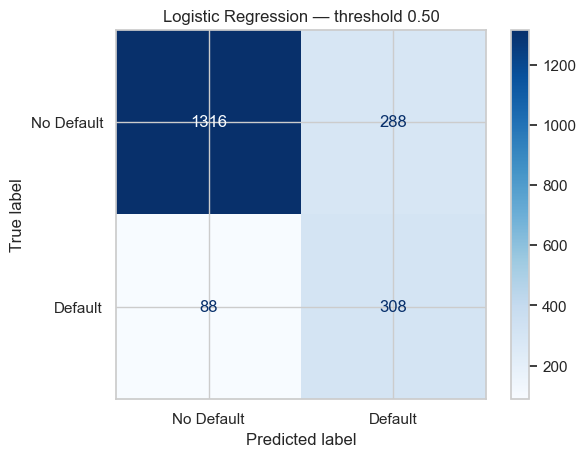


 SVM
              precision    recall  f1-score   support

  No Default       0.90      0.90      0.90      1604
     Default       0.59      0.62      0.61       396

    accuracy                           0.84      2000
   macro avg       0.75      0.76      0.75      2000
weighted avg       0.84      0.84      0.84      2000



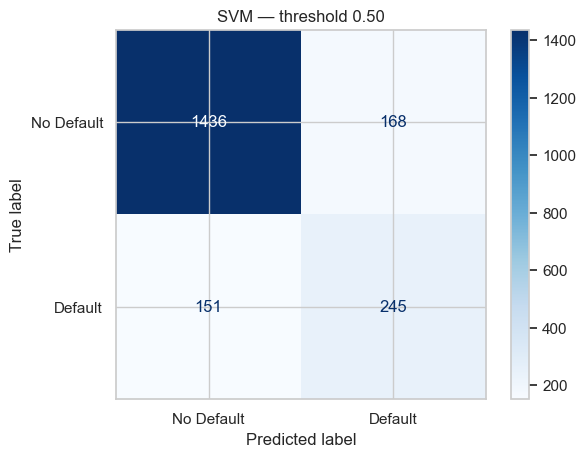


 K-Nearest Neighbors
              precision    recall  f1-score   support

  No Default       0.94      0.56      0.70      1604
     Default       0.32      0.85      0.47       396

    accuracy                           0.62      2000
   macro avg       0.63      0.71      0.58      2000
weighted avg       0.82      0.62      0.65      2000



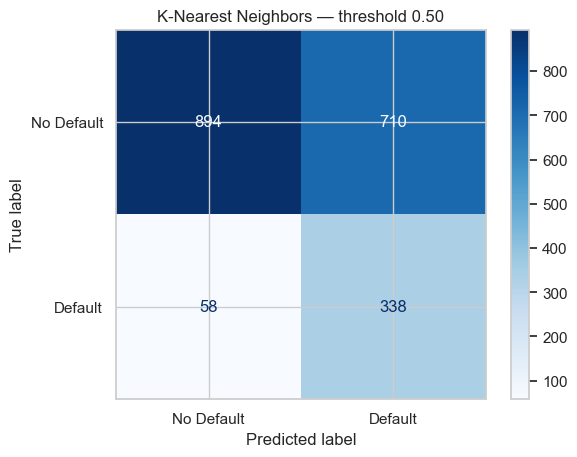


 Decision Tree
              precision    recall  f1-score   support

  No Default       0.89      0.85      0.87      1604
     Default       0.49      0.58      0.53       396

    accuracy                           0.80      2000
   macro avg       0.69      0.72      0.70      2000
weighted avg       0.81      0.80      0.80      2000



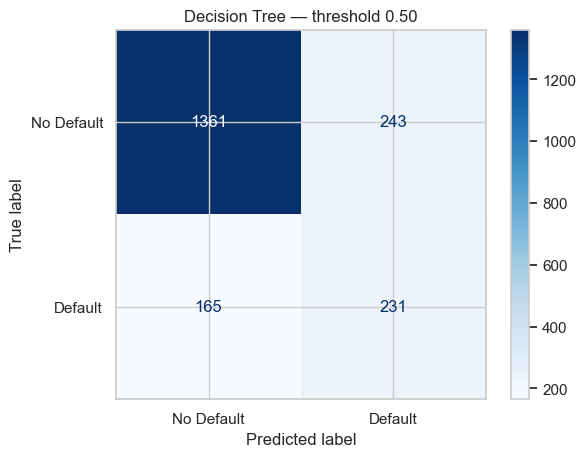


 Discriminant Analysis (LDA)
              precision    recall  f1-score   support

  No Default       0.94      0.82      0.87      1604
     Default       0.52      0.79      0.62       396

    accuracy                           0.81      2000
   macro avg       0.73      0.80      0.75      2000
weighted avg       0.86      0.81      0.82      2000



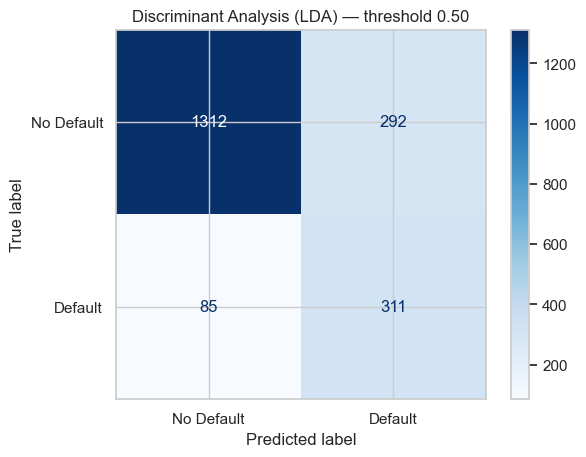


 Naive Bayes
              precision    recall  f1-score   support

  No Default       0.90      0.39      0.54      1604
     Default       0.25      0.83      0.38       396

    accuracy                           0.48      2000
   macro avg       0.58      0.61      0.46      2000
weighted avg       0.77      0.48      0.51      2000



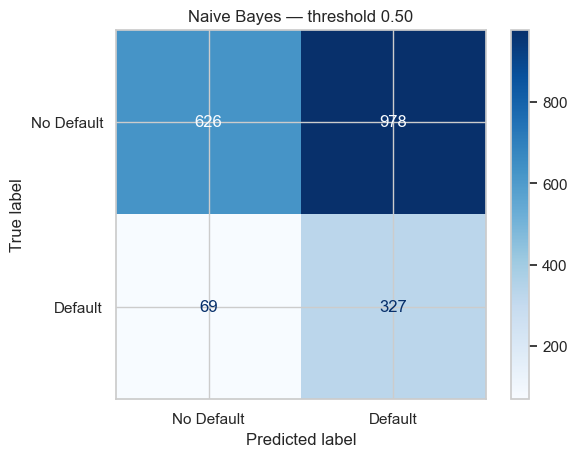

In [53]:
# Confusion matrix for every model at the standard 0.50 threshold.
def positive_probability(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    else:
        return model.decision_function(X)

for name, model in fitted_models.items():
    prob = positive_probability(model, X_test)
    pred = (prob >= 0.50).astype(int)
    print("\n", name)
    print(classification_report(y_test, pred, target_names=["No Default", "Default"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No Default", "Default"], cmap="Blues")
    plt.title(f"{name} — threshold 0.50")
    plt.show()





Top model by PR-AUC: Discriminant Analysis (LDA)
              precision    recall  f1-score   support

  No Default       0.94      0.82      0.87      1604
     Default       0.52      0.79      0.62       396

    accuracy                           0.81      2000
   macro avg       0.73      0.80      0.75      2000
weighted avg       0.86      0.81      0.82      2000



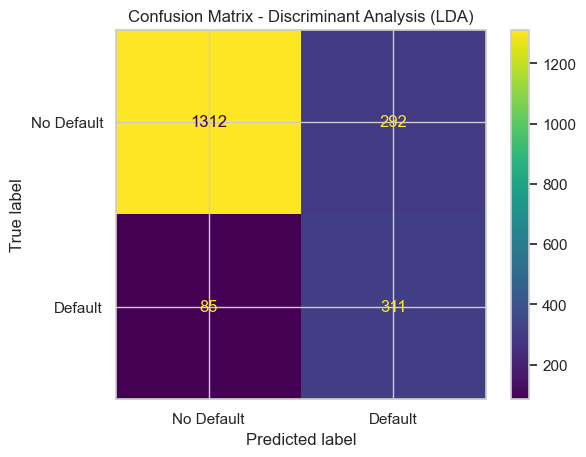

In [54]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
print("Top model by PR-AUC:", best_model_name)

y_pred_best = (best_model.predict_proba(X_test)[:, 1] >= 0.50).astype(int)
print(classification_report(y_test, y_pred_best, target_names=["No Default", "Default"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=["No Default", "Default"])
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

**How to interpret the measures**
- **Recall:** proportion of actual defaulters detected. This is important when missing a defaulter is costly.
- **Precision:** among applicants flagged as defaulters, how many actually default.
- **F1:** balances precision and recall.
- **ROC-AUC:** ranking ability across thresholds.
- **PR-AUC:** especially informative when the positive class is relatively rare.
- **Accuracy:** report it, but do not use it alone to choose the bank's model.

## 15. Compare SMOTE with no-SMOTE baseline

In [55]:
# Logistic Regression baseline without SMOTE; same preprocessing and train/test split.
baseline_lr = SkPipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
baseline_lr.fit(X_train, y_train)

smote_lr = fitted_models["Logistic Regression"]
imbalance_comparison = pd.DataFrame([
    {"Approach": "No SMOTE", **evaluate_binary_model(baseline_lr, X_test, y_test)},
    {"Approach": "SMOTE on training folds", **evaluate_binary_model(smote_lr, X_test, y_test)}
])
display(imbalance_comparison.round(4))

,Approach,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,No SMOTE,0.863,0.7075,0.5253,0.6029,0.8875,0.7058
1,SMOTE on training folds,0.812,0.5168,0.7778,0.6210,0.8853,0.6986


Compare recall and precision, not only accuracy. SMOTE often improves minority-class recall but can reduce precision by producing more false alarms. The actual direction and size of the change must be read from this dataset's output.

## 16. Threshold selection for lending decisions

In [27]:
# Illustrate the trade-off at several probability thresholds.
threshold_rows = []
best_prob = best_model.predict_proba(X_test)[:, 1]
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (best_prob >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "False_Negatives": int(((y_test == 1) & (pred == 0)).sum()),
        "False_Positives": int(((y_test == 0) & (pred == 1)).sum())
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,False_Negatives,False_Positives
0,0.2,0.3697,0.9242,0.5281,30,624
1,0.3,0.4277,0.8737,0.5743,50,463
2,0.4,0.4876,0.8409,0.6172,63,350
3,0.5,0.5168,0.7778,0.6210,88,288
4,0.6,0.5734,0.7298,0.6422,107,215
5,0.7,0.6317,0.6540,0.6427,137,151


A lower threshold generally catches more potential defaulters (higher recall) but may wrongly flag more good borrowers (lower precision). The bank should choose the threshold using the relative financial cost of false negatives and false positives, not by accuracy alone. The table supports that decision; it does not itself establish the bank's cost ratio.

## 17. Tune the strongest candidate (optional)

In [56]:
# Tune Logistic Regression as a reproducible example.
# GridSearchCV refits preprocessing and SMOTE within each training fold.
tuning_pipeline = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__solver": ["liblinear"]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    tuning_pipeline, param_grid, scoring="average_precision",
    cv=cv, n_jobs=-1, refit=True
)
grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation PR-AUC:", round(grid_search.best_score_, 4))
print("Test metrics:")
display(pd.DataFrame([evaluate_binary_model(grid_search.best_estimator_, X_test, y_test)]).round(4))

Best parameters: {'model__C': 0.01, 'model__solver': 'liblinear'}
Best cross-validation PR-AUC: 0.7169
Test metrics:


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,0.8165,0.5245,0.7854,0.6289,0.8857,0.7017


## 18. Separate classification model for Risk_Category

Risk_Category classification report:
              precision    recall  f1-score   support

        High       0.78      0.73      0.75       400
         Low       0.84      0.89      0.86      1003
      Medium       0.63      0.59      0.61       597

    accuracy                           0.77      2000
   macro avg       0.75      0.74      0.74      2000
weighted avg       0.76      0.77      0.77      2000



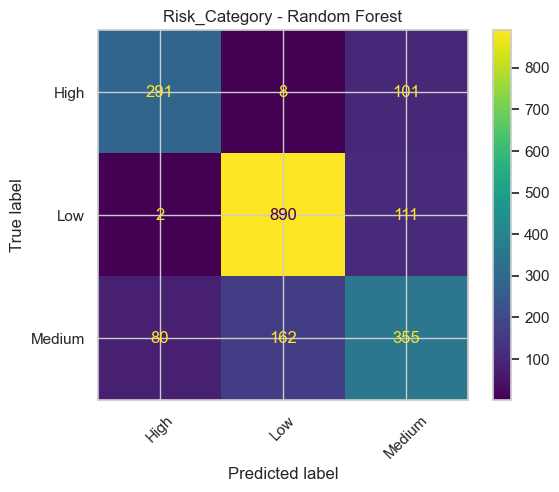

In [57]:
# This is a separate task. Risk_Category is now the target.
# Loan_Default is excluded because it is an outcome and would leak information into risk-category prediction.
risk_drop = ["Risk_Category", "Loan_Default", "Applicant_ID"]
X_risk = df.drop(columns=risk_drop, errors="ignore").copy()
y_risk = df["Risk_Category"].copy()

valid_risk = y_risk.notna()
X_risk = X_risk.loc[valid_risk]
y_risk = y_risk.loc[valid_risk]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_risk, y_risk, test_size=0.20, random_state=RANDOM_STATE, stratify=y_risk
)

num_risk = Xr_train.select_dtypes(include=np.number).columns.tolist()
cat_risk = Xr_train.select_dtypes(exclude=np.number).columns.tolist()

risk_preprocessor = ColumnTransformer(transformers=[
    
    ("num", SkPipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scaler", StandardScaler())]), num_risk),
    ("cat", SkPipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_risk)
], sparse_threshold=0.0)

risk_model = ImbPipeline(steps=[
    ("preprocess", risk_preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                    class_weight="balanced", random_state=RANDOM_STATE,
                                    n_jobs=-1))
])
risk_model.fit(Xr_train, yr_train)
risk_pred = risk_model.predict(Xr_test)

print("Risk_Category classification report:")
print(classification_report(yr_test, risk_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(yr_test, risk_pred, xticks_rotation=45)
plt.title("Risk_Category - Random Forest")
plt.show()

**Important limitation:** This model predicts `Risk_Category` without using `Loan_Default`. If the bank's operational definition of Risk_Category is itself calculated using default outcomes or post-loan behaviour, the model should be interpreted as a prediction of the recorded label, not as proof that the category is an independent risk measure.

## 19. Final conclusions and documentation

In [59]:
print("Loan_Default model ranking (by PR-AUC):")
display(results_df.round(4))
print("\nBest model by PR-AUC:", best_model_name)

Loan_Default model ranking (by PR-AUC):


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Discriminant Analysis (LDA),0.8115,0.5158,0.7854,0.6226,0.8844,0.6995
1,Logistic Regression,0.8120,0.5168,0.7778,0.6210,0.8853,0.6986
2,SVM,0.8405,0.5932,0.6187,0.6057,0.8605,0.6353
3,Decision Tree,0.7960,0.4873,0.5833,0.5310,0.8097,0.5010
4,Naive Bayes,0.4765,0.2506,0.8258,0.3845,0.7461,0.4979
5,K-Nearest Neighbors,0.6160,0.3225,0.8535,0.4681,0.7827,0.4121



Best model by PR-AUC: Discriminant Analysis (LDA)
